# 07-共享资源竞争与临界区保护


## 1. 本篇内容与学习目标

本篇是《FreeRTOS 从入门到实战》十七篇笔记中的第07篇，对应 `12freeRTOS任务资源竞争问题.pptx`，原课标题为**任务资源竞争**。

第06篇解释了任务现场如何保存和恢复。本篇继续看：任务能够正确恢复自己的现场，为什么共享变量的结果仍可能出错？课程先用两个任务累加同一个全局变量复现问题，再分析读、改、写之间的任务切换，最后通过临界区保护修复。

| 课件主线 | 本篇学习内容 |
|---|---|
| 实验场景 | 两个任务各累加20万次，检查共享计数值 |
| 问题本质 | 非原子操作被打断，旧值写回覆盖其他任务的更新 |
| 解决方案 | 成对进入和退出临界区，保护完整的读、改、写过程 |
| 原理与限制 | 端口如何屏蔽中断，任务与ISR接口的区别，临界区长度与阻塞限制 |

以下按PPT顺序整理，保留原课实验代码和教学图。涉及PPT前后不一致的实现描述，就地使用官方FreeRTOS-Kernel V10.5.1的Cortex-M4F端口核对；这一参考版本未被确认为课程源码版本。


## 2. 实验场景：两个任务争用一个全局变量

原课设置全局变量 `n`，初始值为0。`task1` 和 `task2` 都反复执行“读取 `n`、加1、写回 `n`”。两个任务访问的是同一份全局数据。

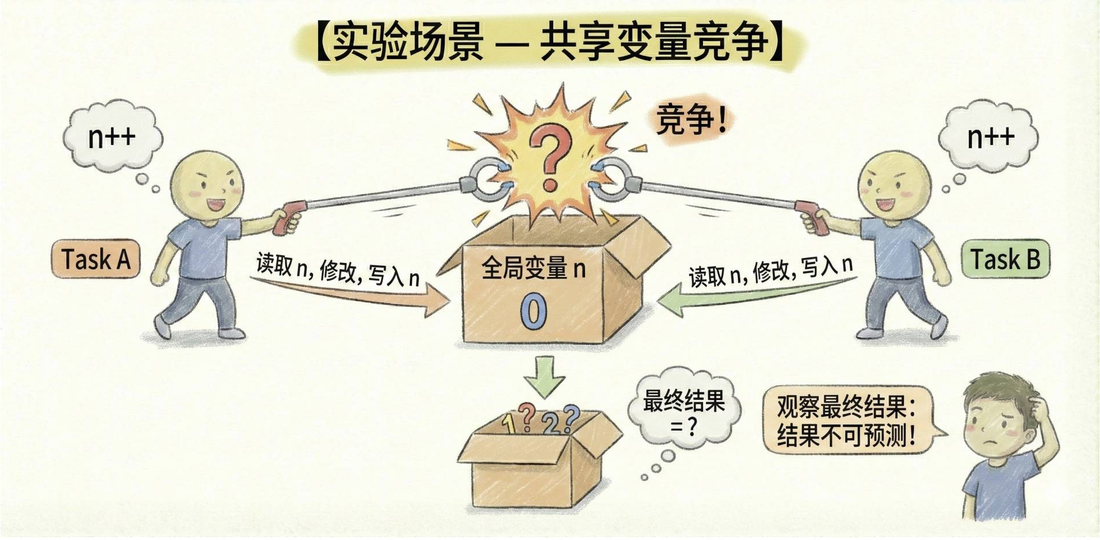

在课程的单核环境中，同一时刻通常只有一个任务执行，但任务可能在一次更新尚未完成时被切换出去。另一个任务在这段间隔内修改同一变量，前一个任务恢复后就可能写回过时结果。

因此，共享资源竞争不要求两个任务真正同时执行指令；只要访问过程交错，并且至少一方修改共享数据，就可能产生冲突。

先区分实验中的变量：

| 变量 | 归属 | 与竞争的关系 |
|---|---|---|
| 全局 `n` | 两个任务共同访问 | 本课需要保护的共享数据 |
| 循环变量 `i` | 各任务自己的局部变量 | 分别记录各自的循环次数 |
| 局部变量 `a` | 各任务自己的局部变量 | 暂存根据旧 `n` 算出的结果，恢复任务后仍可能过时 |

任务切换能够保存 `a` 的现场，却不会自动判断这个 `a` 是否还适合写回共享变量。


## 3. 原课代码：刻意扩大读写之间的间隔

在现有课程工程中，查看定义 `task1`、`task2` 的任务源文件。PPT没有给出该文件的名称，也没有展示本实验的 `xTaskCreate()` 调用参数；这里保留课件实际展示的任务代码，不补造栈大小或优先级。

### task1：读取后延时，再写回

第5页代码如下，仅整理缩进和空格：

```c
int n = 0;

void task1(void *param)
{
    // 任务一定不能返回
    for (int i = 0; i < 200000; i++)
    {
        int a = n + 1;
        delay_1us(1);
        n = a;
    }
    printf("t1:%d\n ", n);
    vTaskDelete(NULL);
}
```

### task2：操作同一个n

第6页代码如下。`n` 只需要定义一份，两个任务都访问它。

```c
void task2(void *param)
{
    // 任务一定不能返回
    for (int i = 0; i < 200000; i++)
    {
        int a = n + 1;
        delay_1us(1);
        n = a;
    }
    printf("t2:%d\n ", n);
    vTaskDelete(NULL);
}
```

`delay_1us(1)` 位于读取、计算与写回之间，用于扩大尚未写回结果的时间窗口，更容易观察任务切换引发的冲突。它是课程已有的延时函数；PPT没有展示实现，不能把它等同于FreeRTOS的 `vTaskDelay()`，也不能据此断言它必定主动切换任务。

循环结束后，各任务打印当时的 `n`，再通过 `vTaskDelete(NULL)` 删除自己。任务入口不能直接返回，这一点与第04、05篇一致。

> 就地补充：这里只是观察竞争的教学片段。实际指令与编译优化有关；分析读写是否发生时，应查看当前工程的反汇编。给变量添加 `volatile` 也不能把完整的读、改、写变成原子操作。


## 4. 预期40万，为什么课程观察到约20万

如果两次任务中的每一次加1都被完整保留下来，那么两个任务都完成后：

```text
最终计数 = 初始值0 + task1的200000次 + task2的200000次
         = 400000
```

第7页给出的课程实验现象是：预期 `N = 400000`，实际 `N ≈ 200000`，明显小于预期。该页的 `N` 指前面代码中的计数变量 `n`。

约20万是课件报告的实验结果，不是本笔记在开发板上的实测，也不是所有调度设置下的固定结果。丢失多少次更新取决于任务的交错过程；如果某次运行恰好没有在危险窗口中切换，也可能暂时得到预期值。

还要区分“任务完成时打印的值”和“两个任务都完成后的最终值”：

- `t1` 或 `t2` 的第一条输出，只表示该任务结束循环时读取到的共享值，另一任务可能还没结束。
- 核对40万时，需要确认两个任务都已完成各自20万次累加，再观察计数变量。
- 一次得到40万不能证明未保护的代码正确；它可能只是这次没有触发冲突。

原课用“逻辑无错，为何结果错误”引出并发问题：单看加法与循环次数没有问题，但**缺少对共享更新过程的同步保护**。这仍然是程序需要修复的设计缺陷，不能因为加法本身正确就忽略它。


## 5. 根本原因：非原子的读、改、写被打断

**原子性**指一个操作对相关并发访问者表现为不可分割的整体。`n++` 或 `n = n + 1` 虽然只是一条C语句，却不因此成为原子更新。

课件将它概括为三个阶段：

| 阶段 | 课件名称 | 正在做什么 |
|---|---|---|
| 读取 | LOAD | 从共享内存中取得 `n` 的旧值 |
| 修改 | ADD | 在寄存器或临时数据中完成加1 |
| 写回 | STORE | 把计算结果写回共享 `n` |

这是理解执行过程的示意，不是保证编译器一定生成恰好三条指令。

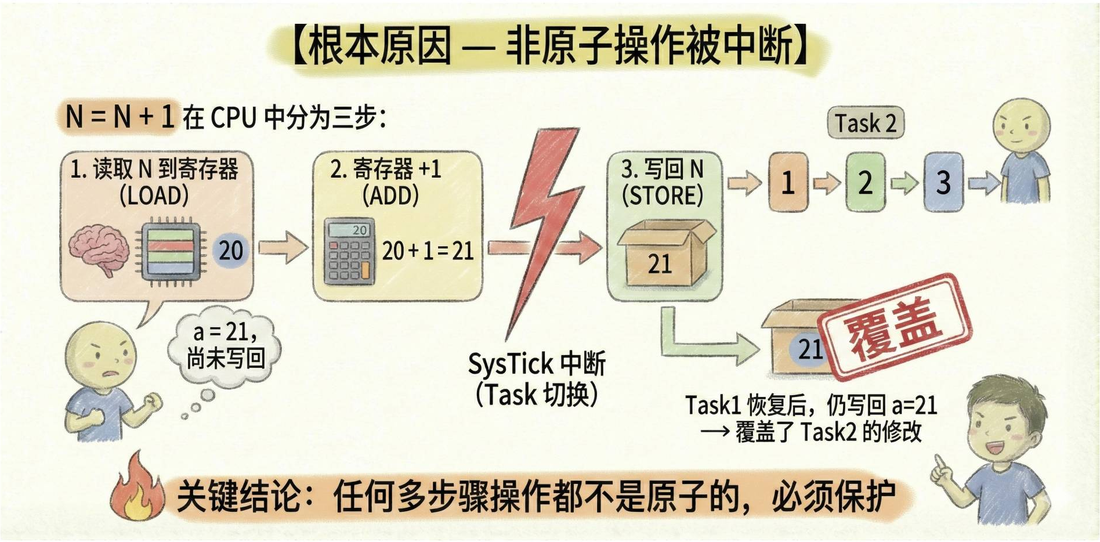

以图中的 `n = 20` 为例：

| 顺序 | 执行者 | 操作 | 共享n |
|---|---|---|---|
| 1 | task1 | 读到20，算出本地 `a = 21`，尚未写回 | 20 |
| 2 | 系统 | 在写回之前发生任务切换 | 20 |
| 3 | task2 | 读到20，算出21，写回 `n = 21` | 21 |
| 4 | task1 | 恢复后继续写回自己的 `a = 21` | 21 |

两个任务各执行一次加1，本应得到22，最后却只有21；有一次更新没有体现在最终结果中。这就是**更新丢失**。如果task2在task1恢复前已完成更多次更新，task1的旧值写回还可能覆盖更大的新值。

第06篇的上下文恢复机制在这里仍然正确：task1确实恢复了自己的 `a = 21`。问题在于共享 `n` 已经变化，而代码仍使用旧计算结果覆盖它。

> 原课图中“多步骤操作必须保护”针对存在冲突的共享访问。各任务独立的局部计算无需都加临界区；需要保护的是可能与其他任务或ISR交错、并破坏共享数据一致性的过程。


## 6. 临界区：把共享更新作为一个整体保护

**临界区**是访问共享资源、需要避免冲突的一段代码。本课使用FreeRTOS的任务上下文接口，在共享操作前进入，在操作完整结束后退出。

```c
taskENTER_CRITICAL();

// 读取、修改、写回共享资源

taskEXIT_CRITICAL();
```

下面保留第9页的进入、执行、退出示意；图中关于底层实现的文字需要结合紧随其后的核对说明阅读。

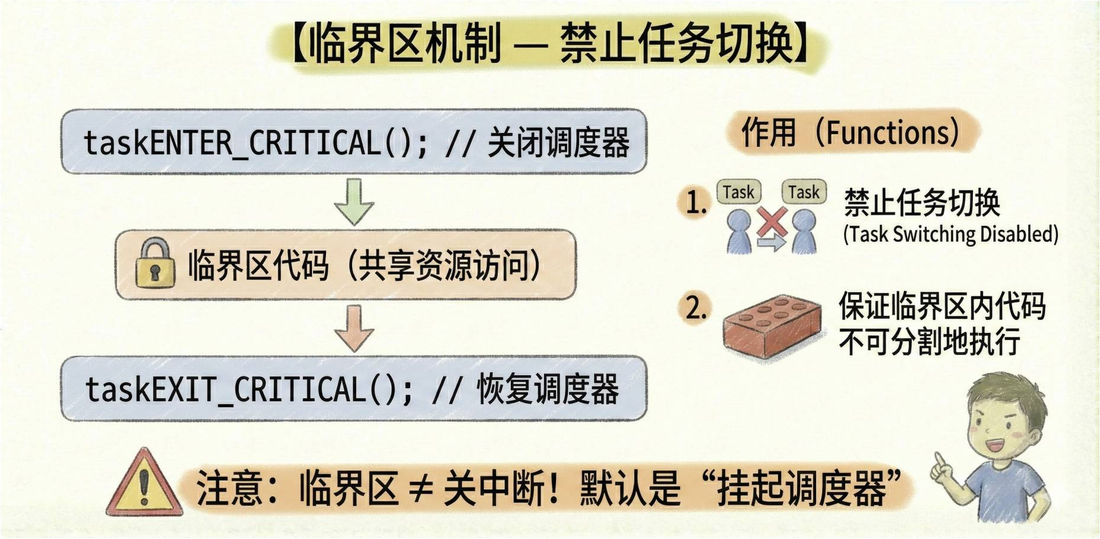

> 原课表述核对：第9页写“默认挂起调度器”，第11页又写Cortex-M移植层通过关中断实现。对本系列使用的Cortex-M4F参考端口，`taskENTER_CRITICAL()` 实际进入端口临界区，通过设置 `BASEPRI` 屏蔽一定优先级范围的中断；它不是调用 `vTaskSuspendAll()` 挂起调度器。临界区内不能发生正常的抢占任务切换，但仍可能有未被屏蔽的高紧迫性中断执行。

保护范围要包含完整的读、改、写。如果先在区外执行 `int a = n + 1;`，再只把 `n = a;` 放进临界区，读取到的旧值仍可能过时，问题没有解决。

所有会冲突的访问路径都要遵循同一保护约定。对本实验，两个任务都需要修改；不能只给其中一个任务加保护。

进入和退出必须配对。不要在进入临界区后直接 `return`、自删任务，或通过其他路径跳过退出，否则中断屏蔽状态可能持续保留，影响调度和响应。


## 7. 修复代码：先完成共享更新，再延时

在原实验的任务源文件中，将每次共享计数的读取、计算和写回放入同一临界区。第10页把变量改名为大写 `N`，任务入口改为 `vTask1`；下面保留该页代码，整理了缩进。

```c
int N = 0;

void vTask1(void *pv)
{
    for (int i = 0; i < 200000; i++)
    {
        taskENTER_CRITICAL();
        int a = N + 1;
        N = a;
        taskEXIT_CRITICAL();

        vTaskDelay(1);
    }
    vTaskDelete(NULL);
}

// Task2 同理
```

与原始代码相比，修改有三个重点：

1. **从读取开始保护**：先进入临界区，再读取 `N`，计算并写回。
2. 移除原来夹在读写之间的 `delay_1us(1)`，让临界区只包含短小的共享更新。
3. 在 `taskEXIT_CRITICAL()` 之后调用 `vTaskDelay(1)`，让任务在保护完成后进入延时阻塞。

`vTaskDelay(1)` 的单位是1个tick，不是固定1毫秒。该延时让任务有机会交替执行；防止更新丢失的是临界区，不能用延时替代同步保护。

第二个任务同样把自己的 `int a = N + 1;` 和 `N = a;` 放入一对进入、退出宏之间，并将延时放在外面。若沿用工程中的旧名称 `n`、`task1`、`task2`，可以保持这些名称，只应用同样的保护逻辑；若采用PPT新名称，需要同步更新任务创建时的入口函数引用。

不要同时保留两份独立的 `n` 和 `N`，让两个任务各累加一份变量；那样就改变了共享资源实验。

当两任务均完成20万次更新，且没有其他访问者修改计数时，预期最终 `N = 400000`。修复页没有显示串口输出代码；可以在调试器中确认两任务完成后的最终值。若保留原实验的打印，打印应放在临界区外，且仍需区分早完成任务的输出和最终值。


## 8. 内部原理：端口屏蔽中断与临界区嵌套

第11页继续解释为何临界区能防止任务交错，以及它对实时性的代价。图中使用了“关闭全局中断”“任务切换依赖SysTick”的概括，下方按当前参考端口限定其含义。

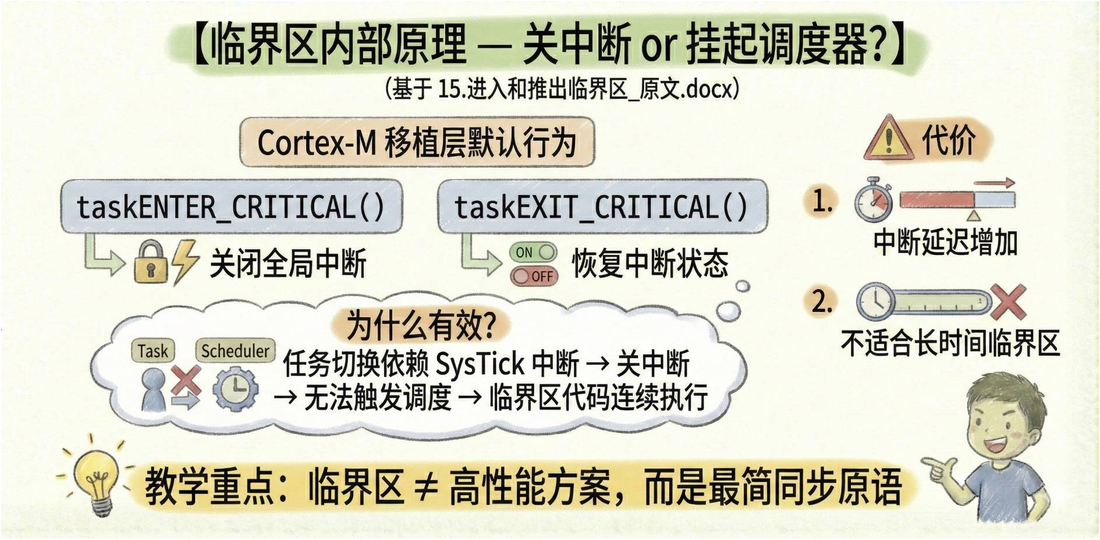

### 从任务宏追到移植端口

就地核对官方FreeRTOS-Kernel V10.5.1：`include/task.h` 中的任务宏调用端口宏，`portable/RVDS/ARM_CM4F/portmacro.h` 再映射到端口函数。与本课直接相关的定义为：

```c
// include/task.h
#define taskENTER_CRITICAL() portENTER_CRITICAL()
#define taskEXIT_CRITICAL()  portEXIT_CRITICAL()

// portable/RVDS/ARM_CM4F/portmacro.h
#define portENTER_CRITICAL()    vPortEnterCritical()
#define portEXIT_CRITICAL()     vPortExitCritical()
#define portDISABLE_INTERRUPTS() vPortRaiseBASEPRI()
#define portENABLE_INTERRUPTS()  vPortSetBASEPRI(0)
```

`port.c` 中，`vPortEnterCritical()` 先屏蔽相应中断，再增加 `uxCriticalNesting`。`vPortExitCritical()` 减少嵌套计数，只有减到0才执行 `portENABLE_INTERRUPTS()`。因此，内层退出不会提前解除外层临界区的保护。

任务临界区支持嵌套，但每一次进入都要有对应退出。它并不等于任意手工关闭中断后，再由退出宏恢复所有先前硬件状态；在这个参考端口，最外层退出将 `BASEPRI` 设为0。应用应使用配对接口，不混用手工中断控制来猜测状态恢复。

### 屏蔽范围与任务切换

`vPortRaiseBASEPRI()` 使用 `configMAX_SYSCALL_INTERRUPT_PRIORITY` 设置屏蔽阈值。它屏蔽的是这一阈值及更低紧迫性的中断，**不是关闭所有中断和异常**；优先级数值更小、紧迫性更高的中断仍可能执行，NMI等也不由这个屏蔽机制阻止。

本端口将SysTick和PendSV配置为最低中断优先级。临界区屏蔽它们，因此不会在读、改、写中间执行正常的抢占上下文切换。课件用SysTick演示一种触发场景；任务切换也可由其他内核操作请求，实际保存与恢复现场由PendSV完成，不能理解为“所有切换都只由SysTick触发”。

挂起调度器是另一组接口：`vTaskSuspendAll()` 和 `xTaskResumeAll()`。它们阻止任务切换而不关闭中断，因此不能据此保护与ISR之间的冲突访问。本课修复仍使用 `taskENTER_CRITICAL()` 和 `taskEXIT_CRITICAL()`。

### 为什么临界区必须短

被屏蔽的中断需要等保护结束才能响应，临界区越长，延迟越大。用它包住20万次循环、串口输出或等待外设，会扩大系统无法及时响应的时间。

本课需要连续执行的只是每次计数更新，所以宏应放在循环内部，只包围必要的几行共享操作。


## 9. 工程限制：不阻塞、少嵌套，ISR使用对应接口

第12页给出以下使用限制：

| 事项 | 本课要求与落实方式 |
|---|---|
| 禁止阻塞 | 临界区内不调用 `vTaskDelay()`、`xQueueReceive()` 等等待或可能引发调度的操作；先退出再等待 |
| 尽量短小 | 只包住完整且必要的共享访问，避免把整个任务处理流程都放进去 |
| 避免嵌套滥用 | 虽支持嵌套，仍尽量保持结构清楚，核对所有退出路径 |
| ISR共享变量 | ISR中使用临界区的 `FROM_ISR` 接口，不调用普通任务的进入、退出宏 |
| 长时间资源保护 | 原课建议使用互斥量（Mutex）；本篇只保留适用性提示，具体用法放在后续课程 |

等待通常要求调度器切走当前任务；临界区正是在阻止此类交错执行，因此不能把需要等待的过程塞进临界区。忙等虽然不一定调用阻塞API，也会延长中断屏蔽时间，不适合长时间放在这里。

### ISR接口要保存并恢复屏蔽值

ISR是中断服务程序。PPT只写“使用FROM_ISR版本”，下面依据同一参考内核补充最小用法，说明进入、退出如何配对；这不是课件中已展示的完整ISR。

```c
// 已满足FreeRTOS中断优先级约束的ISR内部代码片段
UBaseType_t savedMask;

savedMask = taskENTER_CRITICAL_FROM_ISR();
// 在这里完成必要且短小的共享资源访问
taskEXIT_CRITICAL_FROM_ISR(savedMask);
```

进入宏返回之前的屏蔽值，退出时必须传回该值；不能把ISR退出也写成不带参数的普通任务宏。

这个用法还需要满足端口的中断优先级约束：允许使用FreeRTOS接口的ISR，其紧迫性不能高于 `configMAX_SYSCALL_INTERRUPT_PRIORITY` 阈值。高紧迫性ISR不能调用这些接口，并且仍可能打断任务临界区；如果它也修改同一共享数据，仅靠本课这组临界区宏不能消除冲突。

> 原课工程建议：只保护“真正共享”的变量，避免过度保护。在本实验中，保护共享计数的完整更新即可，不需要把每个任务自己的 `i`、串口打印或任务删除一起包进去。


## 10. 本课要点与实验核对

原课第13页回顾了共享变量需要同步、加1不是原子操作、临界区的保护作用、任务与ISR接口区别，以及禁止阻塞和尽量短小的要求。结合前面的端口核对，本课可以归纳为：

- 单核任务交替执行，也可能在共享操作中间形成竞争；正确恢复任务现场不能自动保证共享数据一致。
- 需要保护完整的读、改、写，所有冲突访问者都必须采用一致的保护方式。
- 普通任务成对使用 `taskENTER_CRITICAL()`、`taskEXIT_CRITICAL()`；ISR使用对应的 `FROM_ISR` 宏并保存、传回屏蔽值。
- 对本系列的Cortex-M4F参考端口，任务临界区通过 `BASEPRI` 屏蔽一定范围的中断，挂起调度器属于另一组接口。
- 临界区内不等待、不主动请求调度，保持短小；长时间资源保护按后续课程使用合适的同步机制。

实际在课程工程中核对实验时，按下面顺序进行。以下是依据PPT整理的验证步骤，未进行开发板编译、下载或运行，未伪造串口输出。

1. 在已有任务源文件中确认两任务访问同一份计数变量，初值为0，每个任务循环200000次。保持现有RTOS移植与tick配置。
2. 对照原实验保留读写之间的 `delay_1us(1)`，检查两个任务确实有交错执行机会。记录任务创建参数和调度配置，因为PPT未给出这些条件，不能保证每个工程都会复现约20万。
3. 比较两任务都完成后的最终值与400000；发现偏差时，结合第5节的时间顺序解释更新丢失。若结果恰好正确，不据此判定代码没有竞争。
4. 在两个任务的每次完整共享更新外加成对临界区宏，按修复页将 `vTaskDelay(1)` 放在退出之后；如果改了函数名，同步核对任务创建入口。
5. 再确认两任务均已完成，检查最终计数是否为400000。若仍不符，检查是否仍有区外读取后写回、漏改的另一任务、两份计数变量，或未纳入保护的ISR访问。
6. 最后检查每条执行路径上的进入、退出是否成对，并确认没有把延时、打印、等待或整段循环放进临界区。

本篇重点是修复PPT中的短小共享更新，不展开队列、信号量或互斥量的后续实现。
